# 01 · Perfil e qualidade dos dados

Objetivo: entender o que há em `dados/` antes de modelar. Este notebook **não faz modelagem**. Ele cobre:

1. estrutura, tipos e nulos de cada tabela;
2. integridade entre as tabelas;
3. estrutura do negócio (empresas, escalas, headcount);
4. cobertura real de `fBatidas` e `fAfastamentos`;
5. resumo dos achados e das decisões que eles forçam.

Convenções: "empresa" = `CODCOLIGADA`. `CODFILIAL` é a filial dentro da empresa. Data de corte dos dados: 30/09/2026.

In [1]:
import duckdb, glob, os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 100)

DADOS = '../dados'
con = duckdb.connect()
for f in sorted(glob.glob(f'{DADOS}/*.csv')):
    nome = os.path.basename(f)[:-4]
    con.execute(f"create view {nome} as select * from read_csv('{f}', delim=';', header=true, sample_size=-1)")

def q(sql):
    return con.execute(sql).df()

CORTE = '2026-09-30'
# vinculos ativos na data de corte (admitido ate o corte e sem demissao ate o corte)
con.execute(f"""create view ativos_corte as select * from dim_integrante
    where DATAADMISSAO <= '{CORTE}' and (DATADEMISSAO is null or DATADEMISSAO > '{CORTE}')""")

## 1. Estrutura das tabelas

Observação técnica: os CSVs usam `;` como separador e têm BOM no início.

In [2]:
tabelas = [os.path.basename(f)[:-4] for f in sorted(glob.glob(f'{DADOS}/*.csv'))]
linhas = []
for t in tabelas:
    n = con.execute(f'select count(*) from {t}').fetchone()[0]
    cols = con.execute(f'describe {t}').fetchall()
    linhas.append({'tabela': t, 'linhas': n, 'colunas': len(cols)})
pd.DataFrame(linhas)

,tabela,linhas,colunas
0,dim_empresa,13,4
1,dim_feriados,32,10
2,dim_funcao,10175,4
3,dim_grau_instrucao,13,2
4,dim_horario,1368,7
5,dim_integrante,20001,26
6,dim_meta,8,4
7,dim_motivo_admissao,3,2
8,dim_secao,796,7
9,dim_situacao,11,2


In [3]:
# colunas com nulos, em todas as tabelas
res = []
for t in tabelas:
    for c in con.execute(f'describe {t}').fetchall():
        nn = con.execute(f'select count(*) - count("{c[0]}") from {t}').fetchone()[0]
        if nn:
            res.append({'tabela': t, 'coluna': c[0], 'nulos': nn})
pd.DataFrame(res)

,tabela,coluna,nulos
0,dim_empresa,UF,1
1,dim_integrante,FAIXA_ETARIA,18
2,dim_integrante,CODCCUSTO,349
3,dim_integrante,CODEQUIPE,361
4,dim_integrante,DATADEMISSAO,4921
5,dim_integrante,CATEGORIA_DESLIGAMENTO,4921
6,dim_secao,CODCCUSTO,284
7,dim_secao,CODEQUIPE,420
8,fAfastamentos,DT_FIM,36
9,fBatidas,SITUACAO_NA_DATA,36326


Nulos que importam:

- `DATADEMISSAO` e `CATEGORIA_DESLIGAMENTO` (4.921): vínculo ainda aberto. É esperado.
- `fBatidas.SITUACAO_NA_DATA` (36.326): situação do dia não informada em 6% das linhas.
- `fAfastamentos.DT_FIM` (36): afastamentos em aberto (INSS, aposentadoria, licença).
- `dim_integrante.CODCCUSTO` e `CODEQUIPE`: pouco relevantes para o problema.

## 2. Integridade entre as tabelas

In [4]:
q("""select
 (select count(*) from dim_integrante) vinculos,
 (select count(distinct ID_INTEGRANTE) from dim_integrante) ids_unicos,
 (select count(distinct CODPESSOA||'-'||CODCOLIGADA) from dim_integrante) pessoas,
 (select count(*) from fBatidas) batidas,
 (select count(distinct ID_INTEGRANTE||DATA) from fBatidas) batidas_chave_unica,
 (select count(*) from fBatidas b left join dim_integrante i using(ID_INTEGRANTE) where i.ID_INTEGRANTE is null) batidas_sem_integrante,
 (select count(*) from fAfastamentos a left join dim_integrante i using(ID_INTEGRANTE) where i.ID_INTEGRANTE is null) afast_sem_integrante,
 (select count(*) from dim_integrante i left join dim_horario h using(ID_HORARIO) where h.ID_HORARIO is null) int_sem_horario,
 (select count(*) from dim_integrante i left join dim_funcao f using(ID_FUNCAO) where f.ID_FUNCAO is null) int_sem_funcao,
 (select count(*) from dim_integrante where DATADEMISSAO < DATAADMISSAO) demissao_antes_admissao
""").T.rename(columns={0: 'valor'})

,valor
vinculos,20001
ids_unicos,20001
pessoas,19017
batidas,601474
batidas_chave_unica,601474
batidas_sem_integrante,150
afast_sem_integrante,0
int_sem_horario,0
int_sem_funcao,0
demissao_antes_admissao,1


In [5]:
# batidas sem integrante: quem sao?
q("""select CODCOLIGADA, count(distinct ID_INTEGRANTE) integrantes, count(*) linhas, min(DATA) ini, max(DATA) fim
from fBatidas where ID_INTEGRANTE not in (select ID_INTEGRANTE from dim_integrante) group by 1""")

,CODCOLIGADA,integrantes,linhas,ini,fim
0,6,11,110,2026-09-21,2026-09-30
1,3,1,10,2026-09-21,2026-09-30
2,8,3,30,2026-09-21,2026-09-30


In [6]:
# afastamentos sem DT_FIM: categorias
q("""select a.CATEGORIA_EVENTO, count(*) n, sum((i.ID_INTEGRANTE is null)::int) sem_cadastro
from fAfastamentos a left join dim_integrante i using(ID_INTEGRANTE)
where DT_FIM is null group by 1 order by 2 desc""")

,CATEGORIA_EVENTO,n,sem_cadastro
0,INSS,15,0.0
1,APOSENTADORIA POR INCAPACIDADE,12,0.0
2,LICENCA SEM VENCIMENTO,5,0.0
3,ACIDENTE DE TRABALHO,3,0.0
4,OUTROS,1,0.0


- `ID_INTEGRANTE` é único em `dim_integrante` (20.001 vínculos, 19.017 pessoas distintas dentro da empresa) e não há duplicatas em `fBatidas`.
- **150 linhas de `fBatidas` (15 integrantes) não têm cadastro**, todas de 21 a 30/09/2026 (provavelmente admissões do fim do período ainda não carregadas no cadastro). Impacto desprezível (0,02%).
- **1 vínculo tem demissão antes da admissão** (`8-86991`), erro de cadastro isolado.
- 36 afastamentos não têm `DT_FIM` (INSS, aposentadoria por incapacidade, licença, acidente e outros). Todos têm cadastro. É preciso tratá-los como "em aberto até a data de corte".
- Há 825 pessoas com 2 vínculos, 69 com 3 e 7 com 4. Recontratação é comum e precisa ser tratada na rotatividade.
- 35 demissões são posteriores ao fim do período (01 a 13/10/2026). Usar com cuidado para não vazar informação futura.

## 3. Estrutura do negócio

In [7]:
q("""select e.CODCOLIGADA, count(*) filiais, any_value(e.UF) uf from dim_empresa e group by 1 order by 1""")

,CODCOLIGADA,filiais,uf
0,1,1,GO
1,2,1,NaN
2,3,1,GO
3,4,1,GO
4,5,3,DF
5,6,1,GO
6,7,3,GO
7,8,2,GO


In [8]:
# vinculos, ativos e movimentacao por empresa
q(f"""
select i.CODCOLIGADA empresa,
       count(*) vinculos_historicos,
       sum((DATADEMISSAO is null)::int) sem_demissao,
       (select count(*) from ativos_corte a where a.CODCOLIGADA=i.CODCOLIGADA) ativos_corte,
       sum((year(DATAADMISSAO)=2025)::int) adm_2025,
       sum((year(DATADEMISSAO)=2025)::int) dem_2025,
       sum((year(DATAADMISSAO)=2026)::int) adm_2026_ate_set,
       sum((year(DATADEMISSAO)=2026 and DATADEMISSAO<='{CORTE}')::int) dem_2026_ate_set
from dim_integrante i group by 1 order by 1
""")

,empresa,vinculos_historicos,sem_demissao,ativos_corte,adm_2025,dem_2025,adm_2026_ate_set,dem_2026_ate_set
0,1,337,0.0,0,11.0,15.0,0.0,38.0
1,3,134,113.0,113,27.0,0.0,56.0,21.0
2,4,10,6.0,7,0.0,1.0,6.0,0.0
3,5,6240,2960.0,2971,329.0,191.0,269.0,210.0
4,6,2317,781.0,797,174.0,231.0,545.0,250.0
5,7,51,45.0,45,10.0,0.0,8.0,6.0
6,8,10912,1016.0,1023,338.0,287.0,209.0,328.0


In [9]:
# headcount no fim de cada mes por empresa (vinculo ativo na data)
hc = q("""
with m as (select unnest(generate_series(date '2025-01-31', date '2026-09-30', interval 1 month))::date d)
select CODCOLIGADA empresa, d mes, count(*) headcount
from m join dim_integrante i on i.DATAADMISSAO <= d and (i.DATADEMISSAO is null or i.DATADEMISSAO > d)
group by 1,2 order by 1,2
""")
piv = hc.pivot(index='mes', columns='empresa', values='headcount')
piv.index = pd.to_datetime(piv.index).strftime('%Y-%m')
piv.iloc[[0, 5, 11, 17, 20]]

empresa,1,3,4,5,6,7,8
mes,,,,,,,
2025-01,42.0,53.0,1.0,2768.0,544.0,33.0,1115.0
2025-06,35.0,61.0,1.0,2843.0,482.0,34.0,1122.0
2025-12,38.0,78.0,1.0,2913.0,506.0,43.0,1145.0
2026-06,NaN,108.0,5.0,2905.0,684.0,43.0,1039.0
2026-09,NaN,113.0,7.0,2972.0,798.0,45.0,1023.0


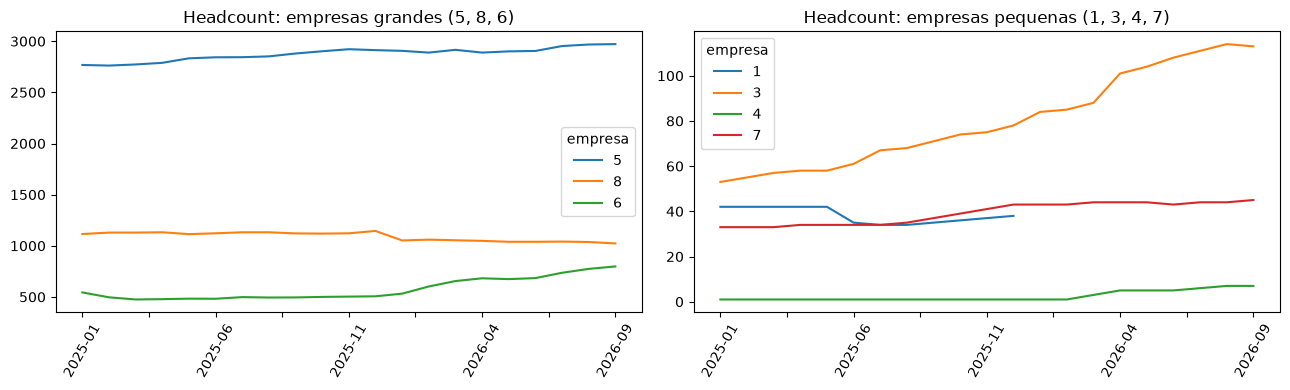

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
piv[[5, 8, 6]].plot(ax=ax[0]); ax[0].set_title('Headcount: empresas grandes (5, 8, 6)'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=60)
piv[[1, 3, 4, 7]].plot(ax=ax[1]); ax[1].set_title('Headcount: empresas pequenas (1, 3, 4, 7)'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

In [11]:
# escalas dos vinculos ativos no corte, por empresa
q("""select a.CODCOLIGADA empresa, h.ESCALA, count(*) ativos from ativos_corte a join dim_horario h using(ID_HORARIO)
group by 1,2 order by 1, 3 desc""").pivot(index='empresa', columns='ESCALA', values='ativos').fillna(0).astype(int)

ESCALA,12X36,5X2,6X1,JORNADA MENSAL,NAO IDENTIFICADA,REVEZAMENTO
empresa,,,,,,
3,0,113,0,0,0,0
4,4,1,1,0,1,0
5,0,1735,1,1235,0,0
6,11,118,634,0,34,0
7,0,8,30,0,7,0
8,9,206,70,0,1,737


In [12]:
# categorias de desligamento (voluntario x involuntario) por empresa
q("""select CODCOLIGADA empresa, CATEGORIA_DESLIGAMENTO, count(*) n from dim_integrante
where DATADEMISSAO is not null group by 1,2 order by 1,2""").pivot(index='empresa', columns='CATEGORIA_DESLIGAMENTO', values='n').fillna(0).astype(int)

CATEGORIA_DESLIGAMENTO,INVOLUNTARIO,VOLUNTARIO
empresa,,
1,238,99
3,16,5
4,3,1
5,2686,594
6,702,834
7,3,3
8,6863,3033


In [13]:
# funcoes mais numerosas entre os ativos no corte
q("""select f.FUNCAO, count(*) ativos from ativos_corte a join dim_funcao f using(ID_FUNCAO) group by 1 order by 2 desc limit 12""")

,FUNCAO,ativos
0,MOTORISTA DE ONIBUS,1972
1,COBRADOR,1106
2,MOTORISTA/CAMINHAO,570
3,OUTRAS FUNCOES,341
4,JOVEM APRENDIZ,229
5,MANOBRISTA,83
6,LAVADOR,55
7,DESPACHANTE,49
8,MECANICO,40
9,BORRACHEIRO,27


- Há **6 empresas com vínculos ativos** (`CODCOLIGADA` 3, 4, 5, 6, 7, 8) e 2 sem ativos (1 e 2). A empresa 2 nem aparece no cadastro. Em `dim_empresa` são 13 filiais.
- **A empresa 5 concentra o quadro** (2.971 dos 4.956 ativos, 60%), seguida pela 8 (1.023). A 6 (797) cresceu de 544 para 798 desde jan/2025.
- A empresa 5 tem escala quase só "JORNADA MENSAL" ou 5X2 e a 8 é dominada por "REVEZAMENTO". Essas escalas não são 6x1 nem 5x2, e isso afeta a Trilha 3.
- Funções dominantes: motorista de ônibus (1.972 ativos) e cobrador (1.106).

## 4. Cobertura de `fBatidas` e `fAfastamentos`

In [14]:
# integrantes com ponto por empresa x ativos no corte
q(f"""
select a.CODCOLIGADA empresa, count(*) ativos_corte,
       count(distinct b.ID_INTEGRANTE) com_ponto_no_periodo
from ativos_corte a left join (select distinct ID_INTEGRANTE from fBatidas) b using(ID_INTEGRANTE)
group by 1 order by 1
""")

,empresa,ativos_corte,com_ponto_no_periodo
0,3,113,83
1,4,7,6
2,5,2971,0
3,6,797,765
4,7,45,42
5,8,1023,248


In [15]:
# cobertura por funcao (top 12 em ativos)
q("""
select f.FUNCAO, count(*) ativos, count(distinct b.ID_INTEGRANTE) com_ponto,
       round(100.0*count(distinct b.ID_INTEGRANTE)/count(*), 1) pct_com_ponto
from ativos_corte a join dim_funcao f using(ID_FUNCAO)
left join (select distinct ID_INTEGRANTE from fBatidas) b using(ID_INTEGRANTE)
group by 1 order by 2 desc limit 12
""")

,FUNCAO,ativos,com_ponto,pct_com_ponto
0,MOTORISTA DE ONIBUS,1972,46,2.3
1,COBRADOR,1106,0,0.0
2,MOTORISTA/CAMINHAO,570,566,99.3
3,OUTRAS FUNCOES,341,177,51.9
4,JOVEM APRENDIZ,229,66,28.8
5,MANOBRISTA,83,29,34.9
6,LAVADOR,55,0,0.0
7,DESPACHANTE,49,0,0.0
8,MECANICO,40,8,20.0
9,BORRACHEIRO,27,11,40.7


In [16]:
# empresas presentes em cada fato (periodo 2025-2026)
q("""
select e.CODCOLIGADA empresa,
  (select count(distinct ID_INTEGRANTE) from fBatidas b where b.CODCOLIGADA=e.CODCOLIGADA) integrantes_em_batidas,
  (select count(*) from fAfastamentos a where a.CODCOLIGADA=e.CODCOLIGADA and DT_INICIO>='2025-01-01') eventos_afastamento
from (select distinct CODCOLIGADA from dim_integrante) e order by 1
""")

,empresa,integrantes_em_batidas,eventos_afastamento
0,1,39,74
1,3,98,188
2,4,6,2
3,5,0,0
4,6,1254,2952
5,7,46,99
6,8,457,1265


In [17]:
# afastamentos por categoria (inicio em 2025-2026): quantidade e duracao media
q("""select CATEGORIA_EVENTO, count(*) eventos, count(distinct ID_INTEGRANTE) integrantes,
round(avg(DT_FIM - DT_INICIO), 1) duracao_media_dias
from fAfastamentos where DT_INICIO>='2025-01-01' group by 1 order by 2 desc""")

,CATEGORIA_EVENTO,eventos,integrantes,duracao_media_dias
0,DOENCA ATE 15 DIAS (EMPRESA),2373,790,1.1
1,FERIAS,1253,778,25.8
2,DESLIGAMENTO,765,745,0.0
3,INSS,101,57,62.4
4,ACIDENTE DE TRABALHO,63,48,25.2
5,APOSENTADORIA POR INCAPACIDADE,9,9,NaN
6,OUTROS,7,7,141.3
7,AVISO PREVIO,7,6,20.1
8,LICENCA SEM VENCIMENTO,2,2,31.0


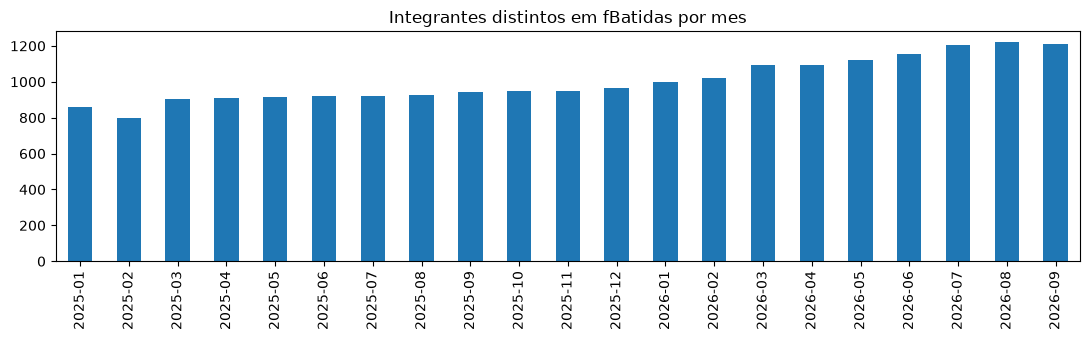

In [18]:
# integrantes distintos com ponto por mes (a amostra cresce ao longo do tempo)
cob = q("""select strftime(DATA,'%Y-%m') mes, count(distinct ID_INTEGRANTE) integrantes_com_ponto from fBatidas group by 1 order by 1""")
ax = cob.set_index('mes').plot(kind='bar', legend=False, figsize=(11, 3.5), title='Integrantes distintos em fBatidas por mes')
ax.set_xlabel(''); plt.tight_layout(); plt.show()

**A cobertura do ponto é parcial e enviesada:**

- `fBatidas` tem só **1.900 dos 20.001 vínculos**, e só 6 das empresas aparecem.
- A **empresa 5 (a maior, 2.971 ativos) não tem nenhuma linha em `fBatidas` nem em `fAfastamentos`** no período.
- Quase só motorista de caminhão está coberto (566 de 570 ativos). Entre os 1.972 motoristas de ônibus, só 46 têm ponto, e entre os 1.106 cobradores, nenhum.
- A empresa 8 (a 2ª maior) tem ponto de 248 dos 1.023 ativos. Falta a maior parte dos motoristas de ônibus.
- Em `fAfastamentos` (2025 em diante), as empresas 6 (2.952 eventos) e 8 (1.265) têm volume relevante. A empresa 5 tem 0 eventos e a 4, só 2.

Consequência: **qualquer taxa de ausência (Trilha 2) estimada com o ponto vale, na prática, para a empresa 6 e para poucas funções das demais.** Estender para o resto exige uma premissa explícita.

## 5. Qualidade do ponto diário

In [19]:
q("""select h.ESCALA, count(*) linhas, count(distinct b.ID_INTEGRANTE) integrantes,
round(avg((MINUTOS_PREVISTOS=0)::int), 3) pct_dias_sem_previsto, round(avg(MINUTOS_PREVISTOS)) previsto_medio_min
from fBatidas b join dim_horario h using(ID_HORARIO) group by 1 order by 2 desc""")

,ESCALA,linhas,integrantes,pct_dias_sem_previsto,previsto_medio_min
0,6X1,364552,1318,0.284,307.0
1,5X2,216239,1270,0.388,290.0
2,12X36,12067,33,0.581,276.0
3,NAO IDENTIFICADA,8559,133,0.294,263.0
4,REVEZAMENTO,57,5,1.000,0.0


In [20]:
q("""select SITUACAO_NA_DATA situacao, count(*) linhas, round(avg(MINUTOS_PREVISTOS)) previsto,
round(avg(MINUTOS_FALTA)) falta, round(avg(MINUTOS_ABONO)) abono, round(avg(MINUTOS_TRABALHADOS)) trabalhado
from fBatidas group by 1 order by 2 desc""")

,situacao,linhas,previsto,falta,abono,trabalhado
0,A,486925,342.0,11.0,7.0,314.0
1,F,37915,71.0,5.0,1.0,60.0
2,NaN,36326,214.0,21.0,16.0,213.0
3,P,20643,118.0,2.0,97.0,19.0
4,D,8466,33.0,5.0,17.0,28.0
5,I,4161,0.0,0.0,0.0,0.0
6,T,3128,37.0,1.0,33.0,3.0
7,L,2712,0.0,0.0,0.0,0.0
8,M,582,0.0,0.0,0.0,0.0
9,E,516,0.0,0.0,0.0,0.0


In [21]:
q("""select
 sum((MINUTOS_PREVISTOS>0)::int) dias_com_jornada,
 sum((MINUTOS_FALTA>0)::int) dias_com_falta,
 sum((MINUTOS_ABONO>0)::int) dias_com_abono,
 sum((MINUTOS_PREVISTOS=0 and MINUTOS_TRABALHADOS>0)::int) trabalho_em_dia_de_folga,
 sum((MINUTOS_EXTRA>0)::int) dias_com_hora_extra
from fBatidas""").T.rename(columns={0: 'dias'})

,dias
dias_com_jornada,404500.0
dias_com_falta,12937.0
dias_com_abono,17358.0
trabalho_em_dia_de_folga,7109.0
dias_com_hora_extra,143466.0


In [22]:
q("""select s.SITUACAO_NA_DATA, d.DESCRICAO from (select distinct SITUACAO_NA_DATA from fBatidas) s
left join dim_situacao d on d.CODSITUACAO = s.SITUACAO_NA_DATA order by 1""")

,SITUACAO_NA_DATA,DESCRICAO
0,A,Ativo
1,D,Demitido
2,E,Afastado
3,F,Férias
4,I,Afastado
5,L,Afastado
6,M,Afastado
7,P,Afastado
8,T,Afastado
9,V,Aviso Prévio


- Na escala 6x1, 28% dos dias têm previsto = 0 (folga), na 5x2, 39%. É o esperado e **a folga da escala não é ausência**.
- `SITUACAO_NA_DATA` distingue o dia (A ativo, F férias, P/I/T/L/M/E/Y afastamentos). Nos dias de férias ou afastamento o previsto médio é baixo ou zero, então dá para separar a ausência planejada da não planejada.
- Há 7.109 dias com trabalho em dia sem jornada prevista (hora extra em folga).
- A escala "REVEZAMENTO" tem 57 linhas, todas com previsto zero. Não serve para modelar.
- Dias de falta (12.937) são muito menos que dias de abono (17.358). Abono cobre atestados e outros motivos, então nem toda ausência vira "falta".

## 6. `dim_meta`

In [23]:
q("""select m.CODCOLIGADA empresa, f.FUNCAO, m.ID_FUNCAO, m.ATUAL, m.META,
round(100.0*(m.META-m.ATUAL)/m.ATUAL, 1) pct_acima,
(select count(*) from ativos_corte a where a.ID_FUNCAO=m.ID_FUNCAO) ativos_corte
from dim_meta m join dim_funcao f using(ID_FUNCAO) order by 1,3""")

,empresa,FUNCAO,ID_FUNCAO,ATUAL,META,pct_acima,ativos_corte
0,5,MOTORISTA DE ONIBUS,5_2270,1117,1137,1.8,1179
1,6,MOTORISTA DE ONIBUS,6_4201,24,25,4.2,24
2,6,MOTORISTA DE ONIBUS,6_4202,22,23,4.5,23
3,6,MOTORISTA/CAMINHAO,6_4204,557,572,2.7,570
4,6,MOTORISTA/VEICULOS LEVES,6_4206,14,16,14.3,15
5,8,MOTORISTA DE ONIBUS,8_1290,561,579,3.2,562
6,8,MOTORISTA DE ONIBUS,8_1291,21,22,4.8,21
7,8,MOTORISTA DE ONIBUS,8_1292,160,170,6.3,163


`dim_meta` traz, para 8 funções de motorista, um quadro `ATUAL` e uma `META` (2% a 14% acima). `ATUAL` coincide com os vínculos **sem data de demissão** no cadastro em 7 das 8 funções, ou seja, é a posição mais recente (até 13/10/2026), e por isso difere um pouco dos ativos em 30/09 da tabela acima. A exceção é a 5_2270 (empresa 5): `ATUAL` = 1.117 contra 1.177 vínculos sem demissão.
O enunciado não explica a tabela. Provavelmente é o quadro-alvo para o contrato. **Vale perguntar à organização o que é a `META`**, porque pode ser a referência que a SIAN usa para comparar a nossa estimativa.

## 7. Resumo dos achados

| # | Achado | Impacto |
|---|---|---|
| 1 | `fBatidas` cobre 1.900 de 20.001 vínculos, quase só motorista de caminhão da empresa 6 | A taxa de ausência por ponto só é confiável para essa população |
| 2 | A **empresa 5 (2.971 ativos, 60% do quadro)** não tem ponto nem afastamentos no período | T2 e T3 dessa empresa dependem de premissas e de extrapolação |
| 3 | Motoristas de ônibus e cobradores (a maior parte do quadro) quase não têm ponto | Idem |
| 4 | O ponto cobre 21 meses e o contrato dura 36 | O horizonte exige projeção, com tendência e premissas explícitas |
| 5 | Muitas escalas são "JORNADA MENSAL" (empresa 5) ou "REVEZAMENTO" (empresa 8), não 6x1 ou 5x2 | A base para a T3 (6x1 → 5x2) é menor que o quadro total |
| 6 | O quadro varia muito por empresa (6 cresceu 47%, 8 caiu 8%) | A rotatividade deve ser projetada **por empresa**, como pede a T1 |
| 7 | Recontratação é comum (901 pessoas com mais de um vínculo) | Definir se a recontratação conta como admissão e rescisão |
| 8 | `dim_meta` não está documentada | Pedir esclarecimento |
| 9 | Erros pontuais: 1 demissão anterior à admissão, 150 batidas sem cadastro | Tratar e documentar |

## Decisões que os dados forçam (a discutir)

1. **Unidade de análise**: empresa (`CODCOLIGADA`), possivelmente cruzada com função ou escala.
2. **O que fazer com a empresa 5 e com ônibus e cobrador** na T2 e na T3: usar taxas da empresa 6 e da empresa 8, ou de funções semelhantes, ou separar por tipo de ausência com fontes diferentes.
3. **Definição de "quadro a mais"** (absoluto, percentual ou por função).
4. **Como projetar 36 meses** a partir de 21.